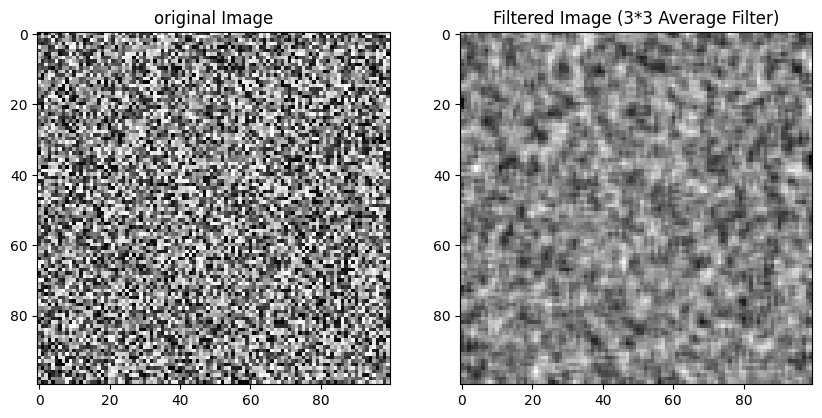

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = np.random.randint(0, 256, (100, 100), dtype=np.uint8)

kernel = np.ones((3, 3), np.float32) / 9.0

filtered_img = cv2.filter2D(img, -1, kernel)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.title("original Image")
plt.imshow(img, cmap='gray')

plt.subplot(1, 2, 1)
plt.title("original Image")
plt.imshow(img, cmap='gray')

plt.subplot(1, 2, 2)
plt.title("Filtered Image (3*3 Average Filter)")
plt.imshow(filtered_img, cmap='gray')

plt.show()

sample_region = np.array([
     [131, 162, 232],
     [104,  93, 139],
     [243,  26, 252]
])

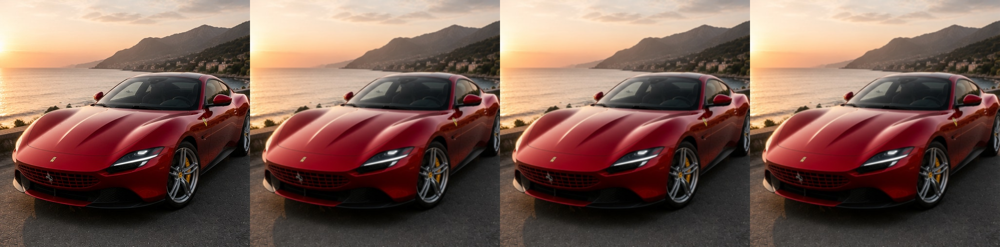

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image = cv2.imread('/페라리.jpeg')

kernel1 = np.array([[1, 2, 1],
                    [2, 4, 2],
                    [1, 2, 1]]) * (1/16)

blurred1 = cv2.filter2D(image, -1, kernel1)

kernel2 = cv2.getGaussianKernel(3, 0)
kernel2 = kernel2 * kernel2.T
blurred2 = cv2.filter2D(image, -1, kernel2)

blurred3 = cv2.GaussianBlur(image, (3, 3), 0)

blurred_images = np.hstack([image, blurred1, blurred2, blurred3])
cv2_imshow(blurred_images)

original, 3, 9, 15


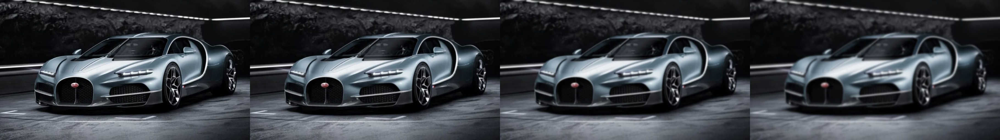

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image = cv2.imread('부가티.jpeg')

blurred = np.hstack([
    image,
    cv2.GaussianBlur(image, (3, 3), 0),
    cv2.GaussianBlur(image, (9, 9), 0),
    cv2.GaussianBlur(image, (15, 15), 0)
])

print("original, 3, 9, 15")
cv2_imshow(blurred)

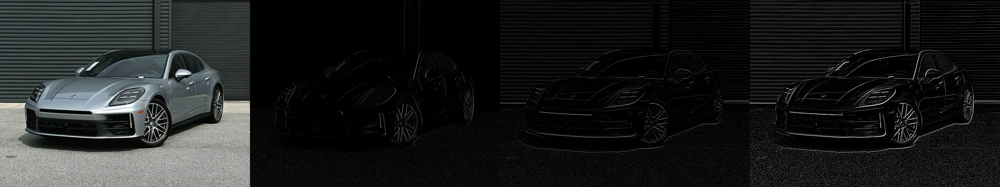

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('포르쉐.jpeg')

gx_kernel = np.array([[-1, 1]])
gy_kernel = np.array([[-1], [1]])

edge_gx = cv2.filter2D(img, -1, gx_kernel)
edge_gy = cv2.filter2D(img, -1, gy_kernel)
edge_gx_gy = cv2.filter2D(img, -1, gx_kernel + gy_kernel)

merged = np.hstack([img, edge_gx, edge_gy, edge_gx_gy])
cv2_imshow(merged)

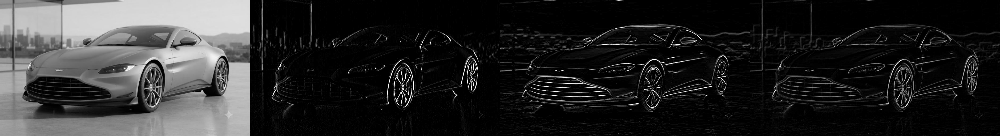

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('에스터마틴.jpeg', cv2.IMREAD_GRAYSCALE)

gx_kernel = np.array([[1, 0, -1],
                      [2, 0, -2],
                      [1, 0, -1]])

gy_kernel = np.array([[1, 2, 1],
                      [0, 0, 0],
                      [-1, -2, -1]])

edge_gx = cv2.filter2D(img, -1, gx_kernel)
edge_gy = cv2.filter2D(img, -1, gy_kernel)
edge_combined = cv2.addWeighted(np.abs(edge_gx), 0.5, np.abs(edge_gy), 0.5, 0)

merged = np.hstack((img, edge_gx, edge_gy, edge_combined))
cv2_imshow(merged)

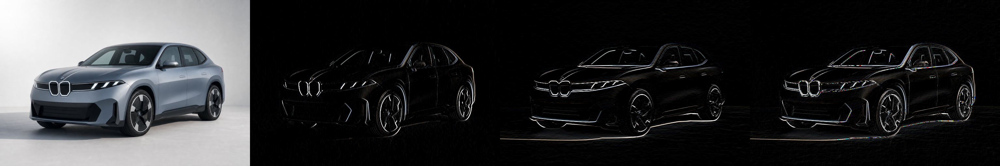

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('bmw.jpeg')

gx_k = np.array([[-1, 0, 1],
                 [-1, 0, 1],
                 [-1, 0, 1]])

gy_k = np.array([[-1, -1, -1],
                 [ 0, 0, 0],
                 [ 1, 1, 1]])

edge_gx = cv2.filter2D(img, -1, gx_k)
edge_gy = cv2.filter2D(img, -1, gy_k)

merged = np.hstack((img, edge_gx, edge_gy, edge_gx + edge_gy))

cv2_imshow(merged)

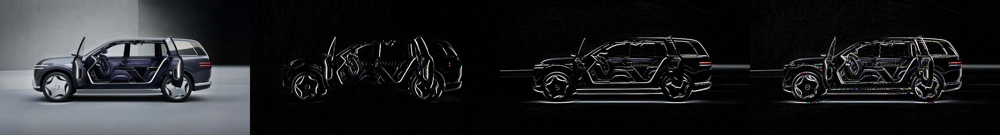

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('gv90.jpeg')

gx_k = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
])

gy_k = np.array([
    [-1, -1, -1],
    [ 0,  0,  0],
    [ 1,  1,  1]
])

edge_gx = cv2.filter2D(img, -1, gx_k)
edge_gy = cv2.filter2D(img, -1, gy_k)

merged = np.hstack((img, edge_gx, edge_gy, edge_gx + edge_gy))

cv2_imshow(merged)

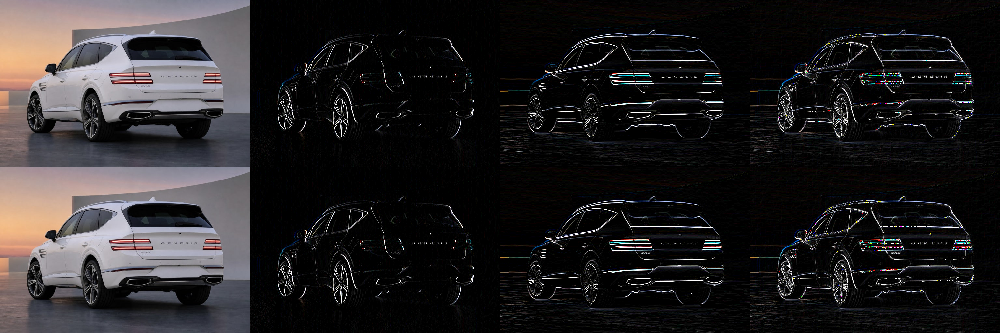

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('gv80.jpeg')

kernel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
])

kernel_y = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
])

kernel_y = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
])

edge_gx = cv2.filter2D(img, -1, kernel_x)
edge_gy = cv2.filter2D(img, -1, kernel_y)

sobel_x = cv2.Sobel(img, -1, 1, 0, ksize=3)
sobel_y = cv2.Sobel(img, -1, 0, 1, ksize=3)

row1 = np.hstack((img, edge_gx, edge_gy, edge_gx + edge_gy))
row2 = np.hstack((img, sobel_x, sobel_y, sobel_x + sobel_y))
merged_grid = np.vstack((row1, row2))

cv2_imshow(merged_grid)

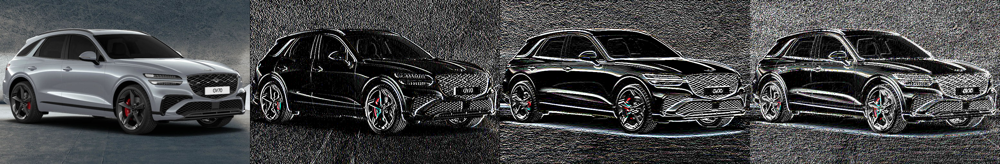

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('gv70.jpeg')

gx_k = np.array([
    [-3,  0,  3],
    [-10, 0, 10],
    [-3,  0,  3]
])

gy_k = np.array([
    [-3, -10, -3],
    [ 0,   0,  0],
    [ 3,  10,  3]
])

edge_gx = cv2.filter2D(img, -1, gx_k)
edge_gy = cv2.filter2D(img, -1, gy_k)

scharrx = cv2.Scharr(img, -1, 1, 0)
scharry = cv2.Scharr(img, -1, 0, 1)

merged1 = np.hstack((img, edge_gx, edge_gy, edge_gx + edge_gy))
merged = np.hstack((img, scharrx, scharry, scharrx + scharry))

cv2_imshow(merged)


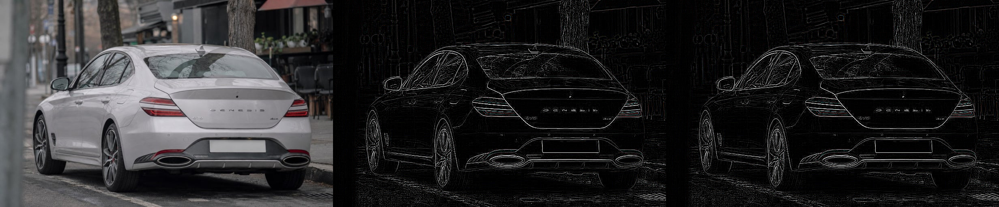

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('g70.jpeg')

laplacian_4 = np.array([[1, 1, 1],
                        [1, -8, 1],
                        [1, 1, 1]], dtype=np.float32)

laplacian_8 = np.array([[1, 1, 1],
                        [1, -8, 1],
                        [1, 1, 1]], dtype=np.float32)

edge_4 = np.abs(cv2.filter2D(img, -1, laplacian_4)).astype(np.uint8)
edge_8 = np.abs(cv2.filter2D(img, -1, laplacian_8)).astype(np.uint8)

merged = np.hstack((img, edge_4, edge_8))

cv2_imshow(merged)

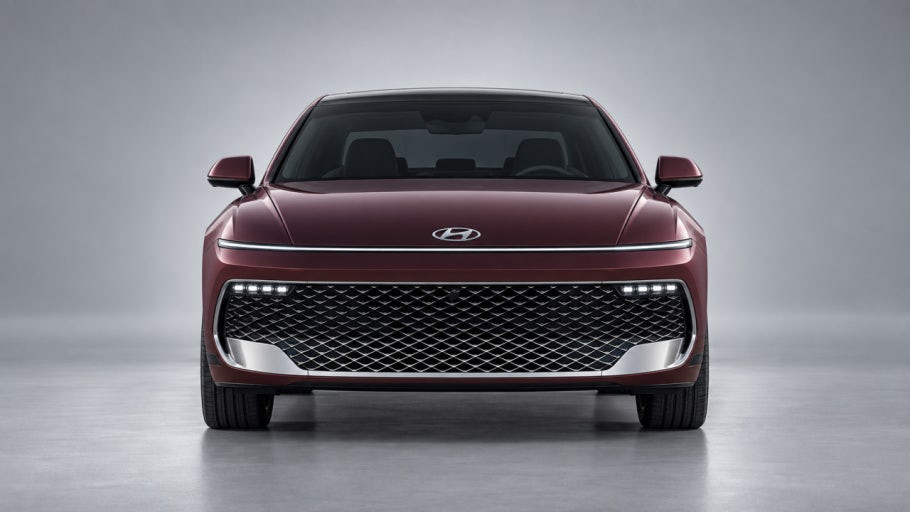

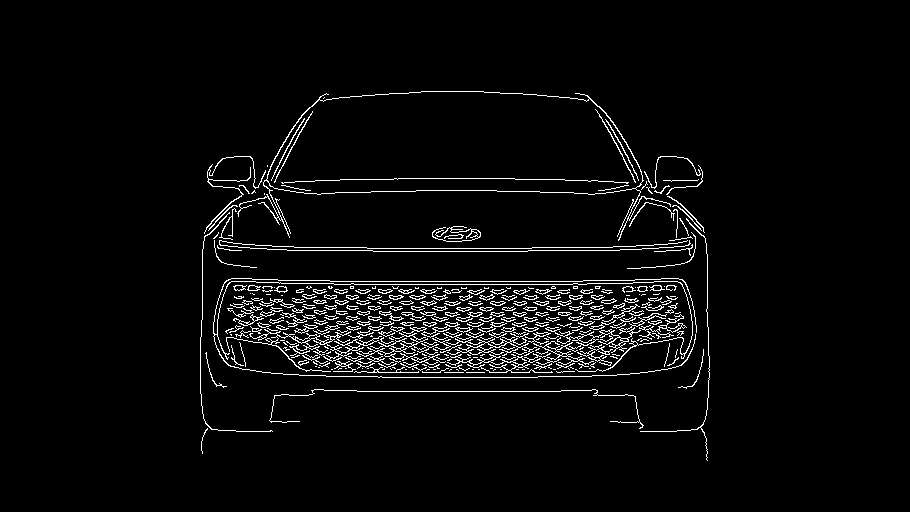

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

def clean_and_load(filename):
    image = cv2.imread(filename)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    return image, blurred

def extract_car_lines(blurred_img, low=50, high=150):
    return cv2.Canny(blurred_img, low, high)

orig, processed = clean_and_load('그랜저.jpeg')

result_edges = extract_car_lines(processed, 70, 150)

cv2_imshow(orig)
cv2_imshow(result_edges)

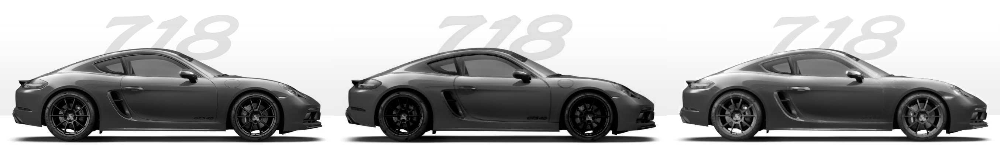

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

def porsche_morphology_lab(image_path):
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

    if img is None:
        return

    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

    eroded = cv2.erode(img, kernel, iterations=1)
    dilated = cv2.dilate(img, kernel, iterations=1)

    comparison_view = np.hstack((img, eroded, dilated))

    cv2_imshow(comparison_view)

porsche_morphology_lab('포르쉐.jpeg')

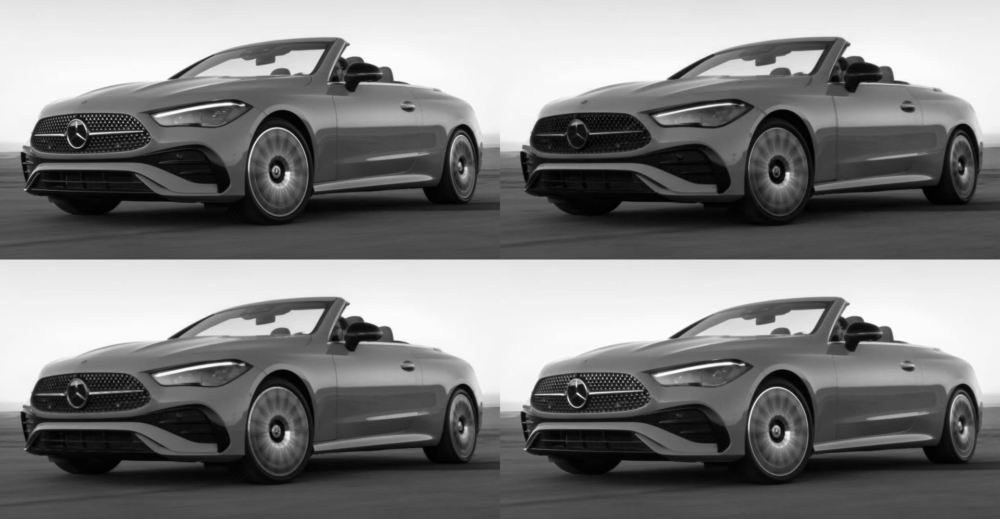

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

def benz_advanced_morphology(image_path):
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

    if img is None:
        return

    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

    eroded = cv2.erode(img, kernel, iterations=1)
    dilated = cv2.dilate(img, kernel, iterations=1)
    opening = cv2.morphologyEx(img, cv2.MORPH_OPEN, kernel)
    closing = cv2.morphologyEx(img, cv2.MORPH_CLOSE, kernel)

    top_row = np.hstack((img, eroded))
    bottom_row = np.hstack((opening, closing))
    grid_view = np.vstack((top_row, bottom_row))

    cv2_imshow(grid_view)

benz_advanced_morphology('벤츠.jpeg')